In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

In [2]:
def infinite_resources(parameters, state_var, dt):
    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations

    new_x_vec = x_vec + dt * (-parameters['α'] * x_vec  + parameters['β'] * xr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] *  x_vec - parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * (parameters['β'] * xr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec


def finite_ribosomes(parameters, state_var, dt):
    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes

    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['β'] * xr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * ( parameters['β'] * xr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec

def finite_protein(parameters, state_var, dt):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes
    y_free = parameters['Y_max'] - np.sum(y_vec) 

    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['β'] * xr_vec* y_free)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec* y_free)
    new_y_vec = y_vec + dt * ( parameters['β'] * xr_vec* y_free - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec


def simulation_wrapper(state0, params, update, sim_time, dt, stop_crit = [100,1e-10]): 
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0], state0.shape[1]])
    states[0] = state0
    stop_t = stop_crit[0]
    stop_min = stop_crit[1]
    stoped = False
    #stopping criteria currently not used, because it doesnt quite work
    
    for t in range(int(sim_time/dt)): 
        states[t+1] = update(params, states[t], dt)
        
    return states[1:]

In [3]:
#set parameters: 
rng = np.random.RandomState(seed = 5)
γ = 0.05
α = 0.1
x_init = 1
dt = 0.001

Rs = np.linspace(0.01,10,20)
Ys = np.linspace(0.1, 5,10)

This simulation shows, that we can achieve the desired relationship as proposed in Seo et al. with and without a competition for aminoacids. However, there is a subtle difference between the models when looking at the change in absolute protein yield. The ribosome only model does not show the surpression of long protein translation, but rather a difference in the amount it increases. 

This shows the competition in the total protein yeald. Interestingly, we dont see the similar competition in the actively translating complexes. However, this might be a limitation of the model as we push elongation and termination into the same step, rather than separate ones. 

Here we see that the protein resource has a start impact by increasing the competition for it. So we actually see the competition in the movement towards the saturated regime. 

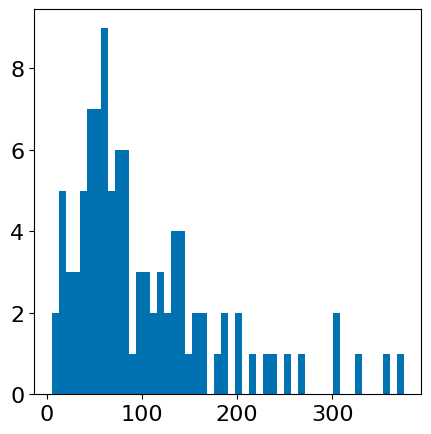

In [4]:
N = 100
Rs = np.linspace(0.01,200,num = 50)
mean, std = 2, 50
rng = np.random.RandomState(seed = 5)
l_samples = rng.gamma(mean, std, N)

fig, ax = plt.subplots(1,1, figsize = (5,5))
ax.hist(l_samples, bins = 50)
plt.show()

l_samples = np.sort(l_samples)

#prepare the different groups for later analyses
b1 = np.nonzero(l_samples < 50)[0][-1]
b2 = np.nonzero(l_samples < 100)[0][-1]
b3 = np.nonzero(l_samples < 150)[0][-1]
b4 = np.nonzero(l_samples < 200)[0][-1]

s_1k = np.arange(0,b1+1,1, dtype = int)
s_2k = np.arange(b1+1,b2+1,1, dtype = int)
s_3k = np.arange(b2+1,b3+1,1, dtype = int)
s_4k = np.arange(b3+1,b4+1,1, dtype = int)
b_4k = np.arange(b4+1,N,1, dtype = int)

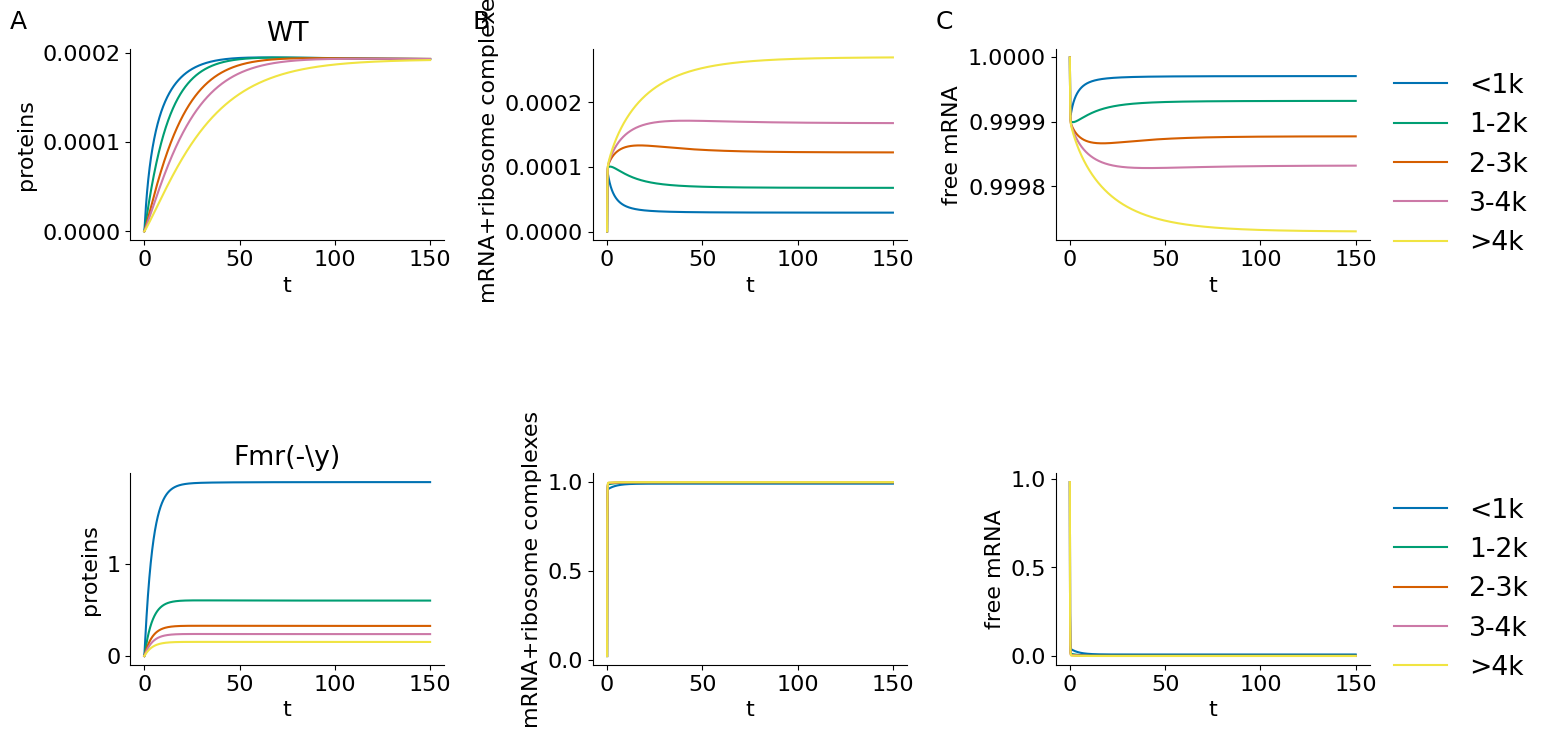

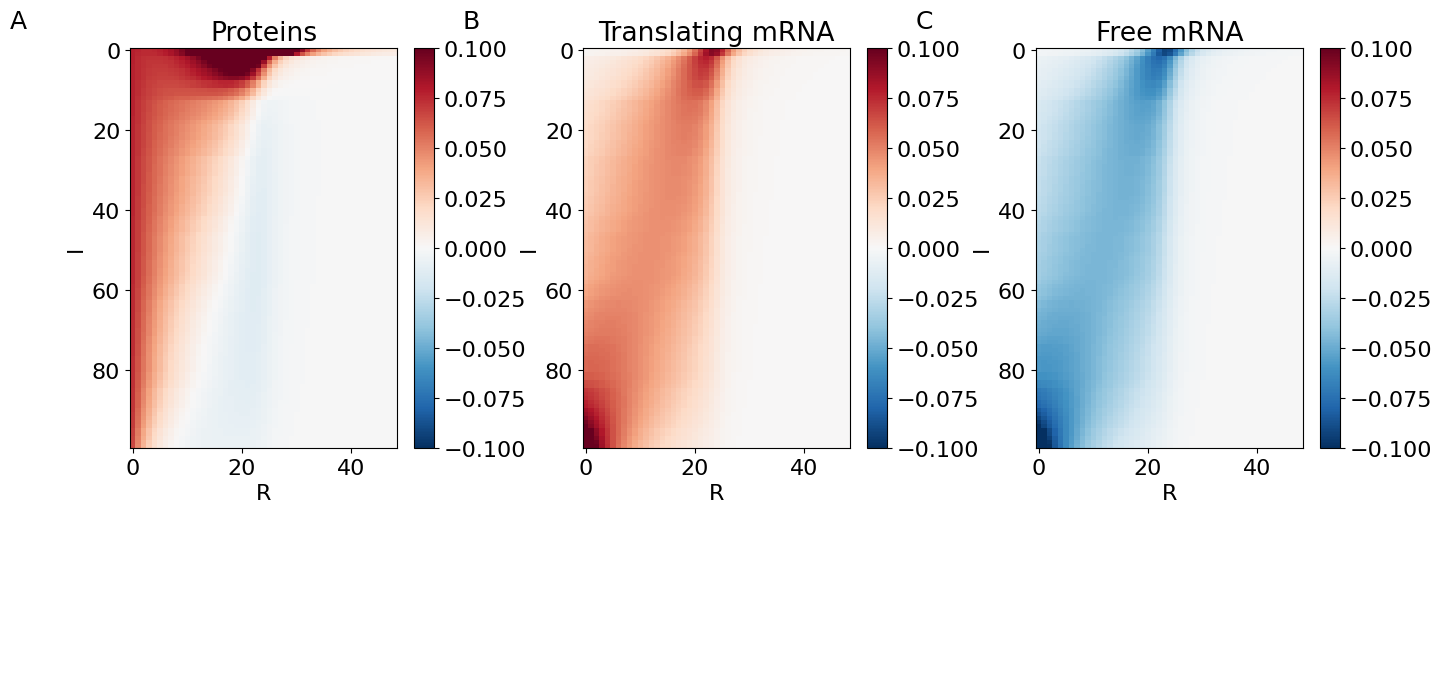

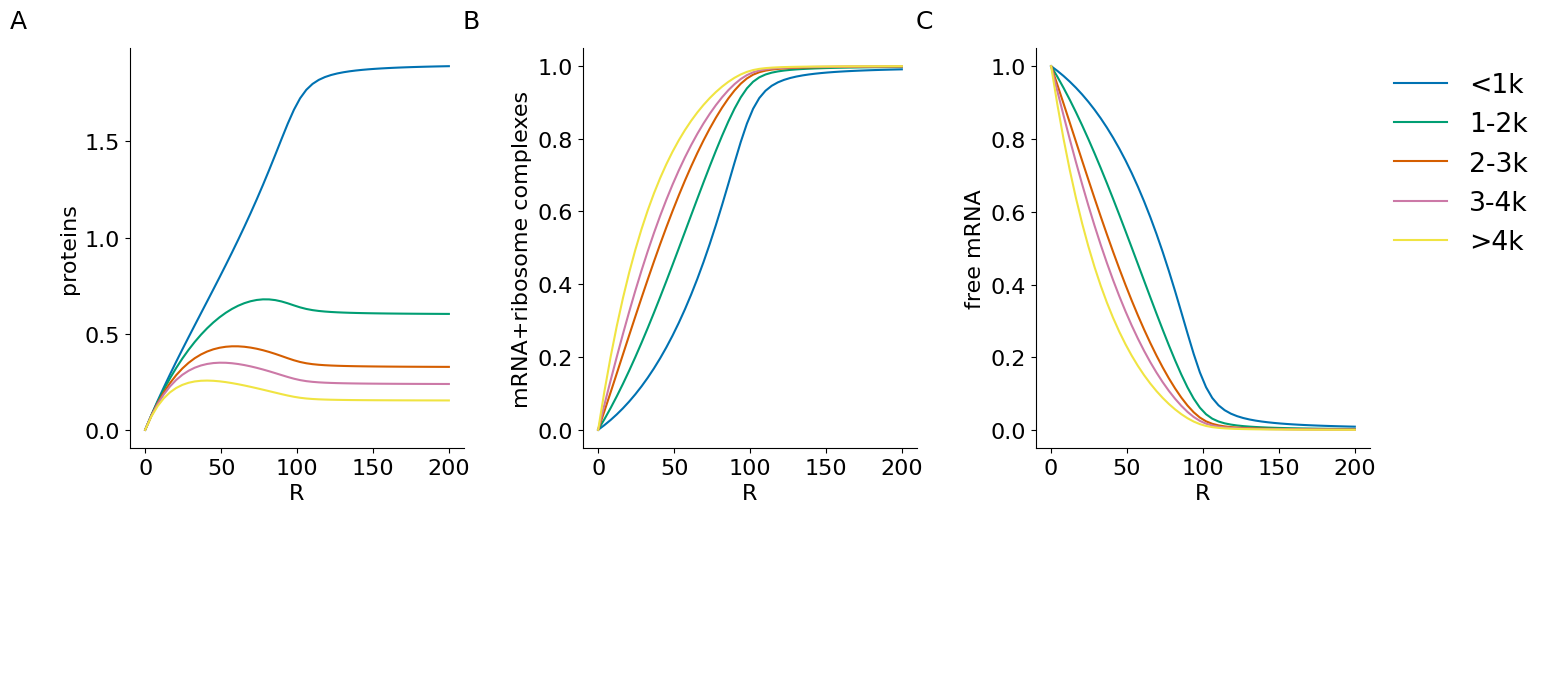

In [5]:
#####sample lengths and show that this is not just a two species competition, but that the competition is increaed
#####when multiple species exists. 



sim_time = 150 #this might be varied per simulation as we need to make sure all simulation reach their steady state
Y = N
results_lp = np.zeros([Rs.shape[0], int(sim_time/dt),3,N])

 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/l_samples
parameters['γ'] = γ
parameters['l'] = l_samples
parameters['Y_max'] =  Y





x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
    results_lp[r]= res
    

    
layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [0,-1]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_lp[ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_lp[ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_lp[ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_lp[ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_lp[ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)

plt.show()



layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()


#normalising the amounts for easier plotting
normed_y = np.diff(results_lp[:,-1,2,:].T, axis = 1) 
normed_xr = np.diff(results_lp[:,-1,1,:].T, axis = 1)
normed_x = np.diff(results_lp[:,-1,0,:].T , axis = 1)

maxy = 0.1 # np.amax(np.abs(normed_y))

    
ax = fig.add_subplot(gs[0,0])
hm = ax.imshow(normed_y, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Proteins')
fig.colorbar(hm, ax = ax )


ax = fig.add_subplot(gs[0,2])
hm = ax.imshow(normed_xr, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Translating mRNA')
fig.colorbar(hm, ax = ax )

ax = fig.add_subplot(gs[0,4])
hm = ax.imshow(normed_x, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('Free mRNA')

plt.show()

layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,-1, 2-i,s_1k], axis = 1)
    av2 = np.mean(results_lp[:,-1, 2-i,s_2k], axis = 1)
    av3 = np.mean(results_lp[:,-1, 2-i,s_3k], axis = 1)
    av4 = np.mean(results_lp[:,-1, 2-i,s_4k], axis = 1)
    av5 = np.mean(results_lp[:,-1, 2-i,b_4k], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)
    
plt.show()

#we safe the results, to be able to do more analyses later
np.save('sim_results/mid_aminolevel_'+str(α)+'_'+str(γ)+'_'+str(Y)+'_full_data.npy', results_lp[:,:,:,:])


We see this competition better in the differences between conditions when looking at a whole population of proteins. We should look at these plots for multiple aminoacid levels. 

**Low Aminoacid environment**

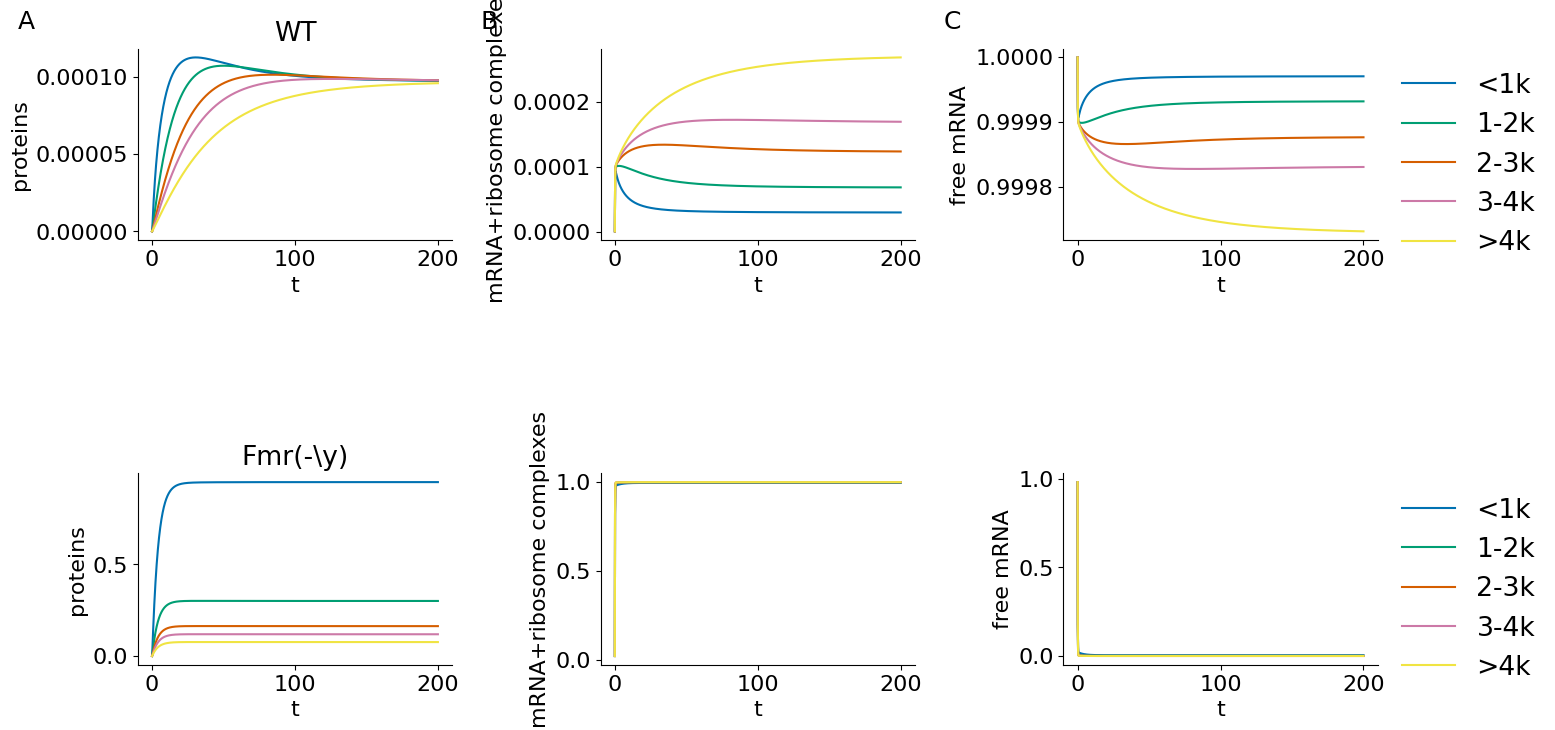

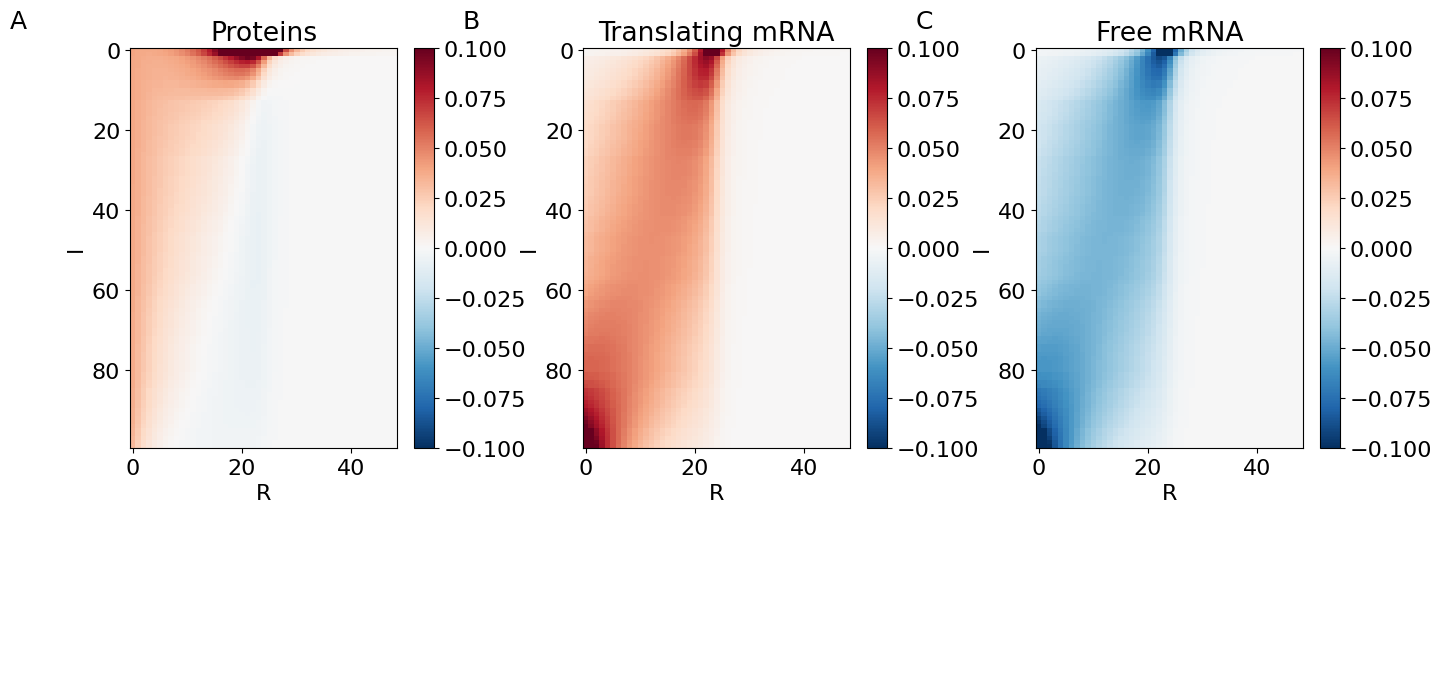

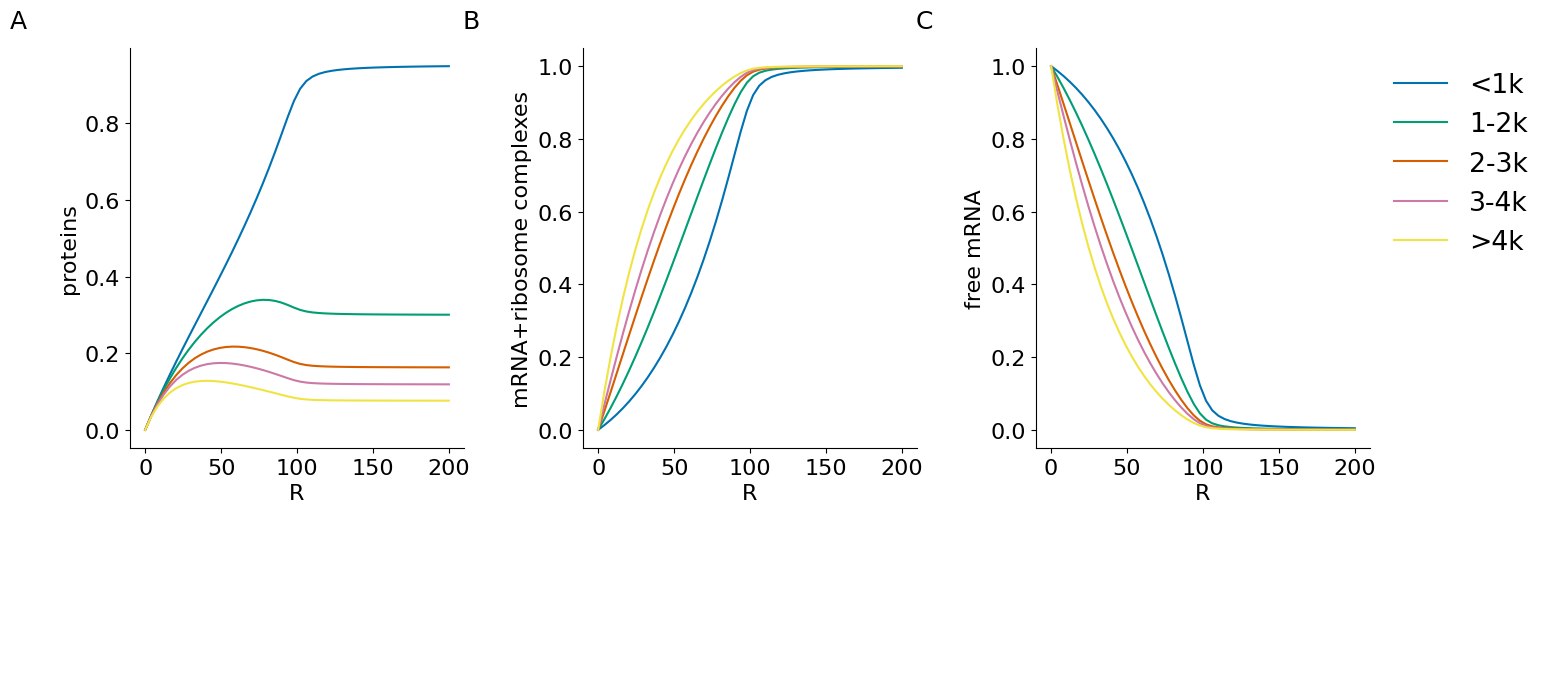

OSError: Not enough free space to write 24000000000 bytes

In [6]:
#####sample lengths and show that this is not just a two species competition, but that the competition is increaed
#####when multiple species exists. 
Y = N/2

sim_time = 200


results_lp = np.zeros([Rs.shape[0], int(sim_time/dt),3,N])
 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/l_samples
parameters['γ'] = γ
parameters['l'] = l_samples
parameters['Y_max'] =  Y

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
    results_lp[r]= res
    

    
layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [0,-1]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_lp[ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_lp[ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_lp[ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_lp[ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_lp[ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)

plt.show()



layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()


#normalising the amounts for easier plotting
normed_y = np.diff(results_lp[:,-1,2,:].T, axis = 1) 
normed_xr = np.diff(results_lp[:,-1,1,:].T, axis = 1)
normed_x = np.diff(results_lp[:,-1,0,:].T , axis = 1)

maxy = 0.1 # np.amax(np.abs(normed_y))

    
ax = fig.add_subplot(gs[0,0])
hm = ax.imshow(normed_y, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Proteins')
fig.colorbar(hm, ax = ax )


ax = fig.add_subplot(gs[0,2])
hm = ax.imshow(normed_xr, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Translating mRNA')
fig.colorbar(hm, ax = ax )

ax = fig.add_subplot(gs[0,4])
hm = ax.imshow(normed_x, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('Free mRNA')

plt.show()

layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,-1, 2-i,s_1k], axis = 1)
    av2 = np.mean(results_lp[:,-1, 2-i,s_2k], axis = 1)
    av3 = np.mean(results_lp[:,-1, 2-i,s_3k], axis = 1)
    av4 = np.mean(results_lp[:,-1, 2-i,s_4k], axis = 1)
    av5 = np.mean(results_lp[:,-1, 2-i,b_4k], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)
    
plt.show()

np.save('sim_results/low_aminolevel_'+str(α)+'_'+str(γ)+'_'+str(Y)+'_full_data.npy', results_lp[:,:,:,:])

#the full data file is too big to be safe on my local disk... think about how to do this. We could subsample, we dont need the full time series. 

**High aminoacid environment**

In [ ]:
#####sample lengths and show that this is not just a two species competition, but that the competition is increaed
#####when multiple species exists. 
Y = N*2

sim_time = 100


results_lp = np.zeros([Rs.shape[0], int(sim_time/dt),3,N])
 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/l_samples
parameters['γ'] = γ
parameters['l'] = l_samples
parameters['Y_max'] =  Y

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
    results_lp[r]= res
    

    
layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [0,-1]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_lp[ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_lp[ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_lp[ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_lp[ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_lp[ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)

plt.show()



layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()


#normalising the amounts for easier plotting
normed_y = np.diff(results_lp[:,-1,2,:].T, axis = 1) 
normed_xr = np.diff(results_lp[:,-1,1,:].T, axis = 1)
normed_x = np.diff(results_lp[:,-1,0,:].T , axis = 1)

maxy = 0.1 # np.amax(np.abs(normed_y))

    
ax = fig.add_subplot(gs[0,0])
hm = ax.imshow(normed_y, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Proteins')
fig.colorbar(hm, ax = ax )


ax = fig.add_subplot(gs[0,2])
hm = ax.imshow(normed_xr, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Translating mRNA')
fig.colorbar(hm, ax = ax )

ax = fig.add_subplot(gs[0,4])
hm = ax.imshow(normed_x, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('Free mRNA')

plt.show()

layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,-1, 2-i,s_1k], axis = 1)
    av2 = np.mean(results_lp[:,-1, 2-i,s_2k], axis = 1)
    av3 = np.mean(results_lp[:,-1, 2-i,s_3k], axis = 1)
    av4 = np.mean(results_lp[:,-1, 2-i,s_4k], axis = 1)
    av5 = np.mean(results_lp[:,-1, 2-i,b_4k], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)
    
plt.show()

np.save('sim_results/high_aminolevel_'+str(α)+'_'+str(γ)+'_'+str(Y)+'_full_data.npy', results_lp[:,:,:,:])

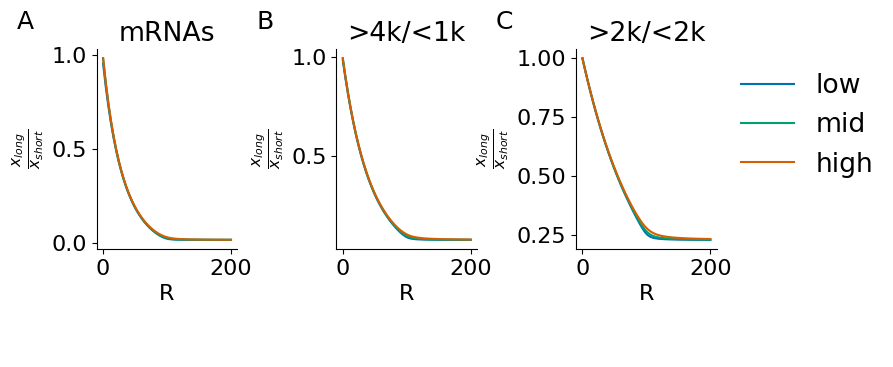

In [7]:
# plot the ratios in the different conditions: we will plot these between groups and maybe individuals

Y = N/2
low = np.load('sim_results/low_aminolevel_'+str(α)+'_'+str(γ)+'_'+str(Y)+'.npy')
Y = N
mid = np.load('sim_results/mid_aminolevel_'+str(α)+'_'+str(γ)+'_'+str(Y)+'.npy')
Y= N*2
high = np.load('sim_results/high_aminolevel_'+str(α)+'_'+str(γ)+'_'+str(Y)+'.npy')

#individuals (shortest vs longest)
layout = '''
    AABBC
    AABBC
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.4,1,0.4,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=.8)
for a in list('ABC'):
    axes[a].set_axis_off()


ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, low[:,2,-1]/low[:,2,0], label = 'low', color = palette[0])
ax.plot(Rs, mid[:,2,-1]/mid[:,2,0], label = 'mid', color = palette[1])
ax.plot(Rs, high[:,2,-1]/high[:,2,0], label = 'high', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('mRNAs')
#changed to be the same as the Osterweil lab paper

ax = fig.add_subplot(gs[0,2])
ax.plot(Rs, np.mean(low[:,2,b_4k], axis = 1)/np.mean(low[:,2,s_1k], axis = 1), label = 'low', color = palette[0])
ax.plot(Rs, np.mean(mid[:,2,b_4k], axis = 1)/np.mean(mid[:,2,s_1k], axis = 1), label = 'mid', color = palette[1])
ax.plot(Rs, np.mean(high[:,2,b_4k], axis = 1)/np.mean(high[:,2,s_1k], axis = 1), label = 'high', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('>4k/<1k')
#changed to be the same as the Osterweil lab paper

short_ind = np.concatenate((s_1k, s_2k), dtype = 'int')
long_ind = np.concatenate((s_3k, s_4k, b_4k), dtype = 'int')

ax = fig.add_subplot(gs[0,4])
ax.plot(Rs, np.mean(low[:,2,long_ind], axis = 1)/np.mean(low[:,2,short_ind], axis = 1), label = 'low', color = palette[0])
ax.plot(Rs, np.mean(mid[:,2,long_ind], axis = 1)/np.mean(mid[:,2,short_ind], axis = 1), label = 'mid', color = palette[1])
ax.plot(Rs, np.mean(high[:,2,long_ind], axis = 1)/np.mean(high[:,2,short_ind], axis = 1), label = 'high', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('>2k/<2k')
#changed to be the same as the Osterweil lab paper
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)

plt.show()


To compare this adequately with the Seo et al. data, we differentiate our species into 5 groups: <1k, 1-2k, 2-3k, 3-4k, >4k. This groups get progressively smaller. These are the second sets of plots above. 

We need to make sure that \alpha < \beta, if we want to be in the same regime as most experiments reports: initiaion limited. 

In [ ]:
#plot example of two in different environments, so we should safe the full data... 

In [ ]:
#add the three 2 population examples given in Fernandes et al. 
Rs = np.linspace(0.01,10,num = 20)

N = 2
x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 
l = np.array([100,500])

ys_bs = np.zeros([Rs.shape[0], N])
ys_lr = np.zeros([Rs.shape[0], N])
ys_sr = np.zeros([Rs.shape[0], N])

parameters = dict()
parameters['α'] = α  #so initiation is the rate limiting step
parameters['β'] = α/l
parameters['γ'] = γ
parameters['l'] = l
parameters['Y_max'] = N * 2


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    
    l = np.array([100,500])
    parameters['l'] = l
    parameters['β'] = α/l

    res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
    ys_bs[r,:]= res[-1,1,:]#res[-1,2,:]
    
    l = np.array([500,2500])
    parameters['l'] = l
    parameters['β'] = α/l

    res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
    ys_lr[r,:]= res[-1,1,:]#res[-1,2,:]
    
    l = np.array([100,2500])
    parameters['l'] = l
    parameters['β'] = α/l

    
    res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
    ys_sr[r,:]= res[-1,1,:]#es[-1,2,:]

        
layout = '''
    AA
    AA
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()


ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, ys_bs[:,1]/ys_bs[:,0], label = '100/500', color = palette[0])
ax.plot(Rs, ys_lr[:,1]/ys_lr[:,0], label = '500/2500', color = palette[1])
ax.plot(Rs, ys_sr[:,1]/ys_sr[:,0], label = '100/2500', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
#changed to be the same as the Osterweil lab paper
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)
plt.show()



Checking what happens when we shift \alpha to be def smaller than \beta. 

If \alpha < \beta for all \beta, no competition is visible. 
However, these arguments also come from experimental evidence, where \beta or the elongation rate is the rate per molecule in the mRNA which means that the total rate in which the initiated ribosome produces a full protein is dependent on the elongation rate by the power of the length of the mRNA. Therefore, assuming that for long mRNA 

In [4]:
l = np.array([1,10])
Y = N*2
N = 2

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

ys_bs = np.zeros([Rs.shape[0], N])
ys_lr = np.zeros([Rs.shape[0], N])
ys_lp = np.zeros([Rs.shape[0], Ys.shape[0], N])

parameters = dict()
parameters['α'] = α
parameters['β'] = α/l
parameters['γ'] = γ
parameters['l'] = l


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]

    res = simulation_wrapper(init_state,parameters,infinite_resources, sim_time, dt) 
    ys_bs[r,:]= res[-1,2,:]

    res = simulation_wrapper(init_state,parameters,finite_ribosomes, sim_time, dt) 
    ys_lr[r,:]= res[-1,2,:]
    
    for y in range(Ys.shape[0]):
        parameters['Y_max'] = Ys[y]
        res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
        ys_lp[r,y,:]= res[-1,2,:]

        
layout = '''
    AA
    AA
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()


ax = fig.add_subplot(gs[0,0])
asr = np.linspace(0.1,1,Ys.shape[0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, ys_lp[:,y,1]/ys_lp[:,y,0],color = palette[2], alpha = asr[y])
ax.plot(Rs, ys_bs[:,1]/ys_bs[:,0], label = 'no limitation', color = palette[0])
ax.plot(Rs, ys_lr[:,1]/ys_lr[:,0], label = 'limited ribosomes', color = palette[1])
ax.plot(Rs, ys_lp[:,y,1]/ys_lp[:,y,0], label = 'limited ribosomes + aminoacids', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)

plt.show()


KeyboardInterrupt: 

In [ ]:
results_lr = np.zeros([Rs.shape[0], N,3])
results_lp = np.zeros([Rs.shape[0],Ys.shape[0], N,3])
 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/l
parameters['γ'] = γ
parameters['l'] = l
parameters['Y_max'] = Y

for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]

    res = simulation_wrapper(init_state,parameters,finite_ribosomes, sim_time, dt) 
    results_lr[r]= res[-1].T
    
    for y in range(Ys.shape[0]):
        parameters['Y_max'] = Ys[y]
        res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
        results_lp[r,y]= res[-1].T

layout = '''
    AAAAA
    AAAAA
    BBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()


maxy = np.amax([np.amax(results_lp[:,:,:,2]),np.amax(results_lr[:,:,2])])
    
ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, results_lr[:,1,2], label = 'long', color = palette[0])
ax.plot(Rs, results_lr[:,0,2], label = 'short', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$y$')
ax.set_ylim(0, maxy)
clear_axes(ax)

ax = fig.add_subplot(gs[2,0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,2], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,2], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$y$')
ax.set_ylim(0, maxy)
clear_axes(ax)

ax = fig.add_subplot(gs[0,2])
maxxr = np.amax([np.amax(results_lp[:,:,:,1]),np.amax(results_lr[:,:,1])])
ax.plot(Rs, results_lr[:,1,1], label = 'long', color = palette[0])
ax.plot(Rs, results_lr[:,0,1], label = 'short', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$xr$')
ax.set_ylim(0, maxxr)
clear_axes(ax)

ax = fig.add_subplot(gs[2,2])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,1], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,1], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$xr$')
ax.set_ylim(0, maxxr)
clear_axes(ax)

ax = fig.add_subplot(gs[0,4])
maxx = np.amax([np.amax(results_lp[:,:,:,0]),np.amax(results_lr[:,:,0])])
ax.plot(Rs, results_lr[:,1,0], label = 'long', color = palette[0])
ax.plot(Rs, results_lr[:,0,0], label = 'short', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$x$')
ax.set_ylim(0, maxx)
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)

ax = fig.add_subplot(gs[2,4])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,0], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,0], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$x$')
ax.set_ylim(0, maxx)
clear_axes(ax)

plt.show()



In [ ]:
Rs = np.linspace(0.01,20,20)
Ys = np.linspace(0.01, 10,20)

results_lp = np.zeros([Rs.shape[0], Ys.shape[0], N,3])

parameters = dict()
parameters['α'] = α
parameters['β'] = α/l
parameters['γ'] = γ
parameters['l'] = l


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    
    for y in range(Ys.shape[0]):
        parameters['Y_max'] = Ys[y]
        res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
        results_lp[r,y]= res[-1].T


layout = '''
    AAAAA
    AAAAA
    BBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()

ax = fig.add_subplot(gs[0,0:4])
asr = np.linspace(0.1,1,Ys.shape[0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,2]/results_lp[:,y,0,2], alpha = asr[y], label = Ys[y])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)



ax = fig.add_subplot(gs[2,0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,2], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,2], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$y$')
clear_axes(ax)

ax = fig.add_subplot(gs[2,2])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,1], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,1], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$xr$')
clear_axes(ax)


ax = fig.add_subplot(gs[2,4])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,0], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,0], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$x$')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)

plt.show()

